# Гипотеза 4: Влияние отношений с руководителем на текучесть персонала

## Данные
Таблица `V4_Employee_cleaned.csv`.

## Цель
Провести проверку гипотезы:  
Нулевая гипотеза (H0): Доля уволившихся в группе с низкой удовлетворенностью (1–2 балла) равна доле уволившихся в группе с высокой удовлетворенностью (4–5 баллов).  
Альтернативная гипотеза (H1): Доля уволившихся в группе с низкой удовлетворенностью (1–2 балла) отличается от доли в группе с высокой удовлетворенностью (4–5 баллов), причем сотрудники с низкой удовлетворенностью уходят чаще.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, norm

# Загрузка данных

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
print(os.listdir('/content/drive/MyDrive'))

print(os.listdir('/content/drive/MyDrive/Проект команды 3'))

path = '/content/drive/MyDrive/Проект команды 3/'
df = pd.read_csv(path + "V4_Employee_cleaned.csv")

Mounted at /content/drive
['Проект команды 3', 'Личное']
['DimDate.txt', 'EducationLevel.csv', 'Employee.csv', 'PerformanceRating.csv', 'RatingLevel.csv', 'SatisfiedLevel.csv', 'V4_Employee_cleaned.csv', 'V4_Проект_команды_3_Предобработка_данных.ipynb', 'Архив', 'Проект_команды_3_Гипотеза_2.ipynb', 'Гипотеза 6.ipynb', 'Проект_команды_3_Проверка гипотезы 1.ipynb', 'Проект_команды_3_Гипотеза_5.ipynb', 'Проект команды 3_Гипотеза 4.ipynb']


## Параметры (фиксируются ДО анализа)

In [4]:
# =================== ПАРАМЕТРЫ (фиксируются ДО анализа) ===================
PRACTICAL_SIGNIFICANCE_PP = 5.0   # порог практически значимого эффекта, п.п.
ALPHA = 0.05                      # уровень значимости
TARGET = "attrition_flag"         # целевой показатель (0 = остался, 1 = уволился)
PREDICTOR = "relationshipsatisfaction"  # удовлетворенность отношениями с руководителем (1–5)
EMPLOYEE_KEY = "employeeid"       # единица наблюдения
# =====================================================================

## 0. Структура данных (единица наблюдения, гранулярность, ключи)

In [5]:
print("=" * 70)
print("0. СТРУКТУРА ДАННЫХ")
print("=" * 70)
print(f"Размер таблицы: {df.shape[0]} строк × {df.shape[1]} столбцов")

print(f"Единица наблюдения: {EMPLOYEE_KEY} (один сотрудник)")
print(f"Ключ уникален: {df[EMPLOYEE_KEY].is_unique}")
print(f"Дубликаты ключа: {df.duplicated(subset=[EMPLOYEE_KEY]).sum()}")
print("Гранулярность: одна строка = один сотрудник, последний доступный опрос")

print("\nТипы ключевых полей:")
for col in [EMPLOYEE_KEY, PREDICTOR, TARGET, "department", "jobrole", "salary_band", "age_group"]:
    if col in df.columns:
        print(f"  {col}: {df[col].dtype}")

0. СТРУКТУРА ДАННЫХ
Размер таблицы: 1470 строк × 46 столбцов
Единица наблюдения: employeeid (один сотрудник)
Ключ уникален: True
Дубликаты ключа: 0
Гранулярность: одна строка = один сотрудник, последний доступный опрос

Типы ключевых полей:
  employeeid: object
  relationshipsatisfaction: float64
  attrition_flag: int64
  department: object
  jobrole: object
  salary_band: object
  age_group: object


## 1. Пропуски, специальные значения и группировка предикатора

In [6]:
print("\n" + "=" * 70)
print("1. ПРОПУСКИ, СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ И ГРУППИРОВКА ПРЕДИКАТОРА")
print("=" * 70)
key_cols = [PREDICTOR, TARGET, "department", "jobrole", "salary_band", "age_group",
            "gender", "overtime", "businesstravel", "worklifebalance"]
for col in key_cols:
    if col in df.columns:
        nan_cnt = int(df[col].isna().sum())
        print(f"  {col}: пропусков = {nan_cnt} ({nan_cnt/len(df)*100:.1f}%)")

print(f"\nДиапазон {PREDICTOR}: {df[PREDICTOR].min()} - {df[PREDICTOR].max()}")
print(f"Уникальные значения {PREDICTOR}: {sorted(df[PREDICTOR].dropna().unique())}")
print(f"Уникальные значения {TARGET}: {sorted(df[TARGET].dropna().unique())}")

# Проверка невозможных значений
bad_pred = df[~df[PREDICTOR].isin([1, 2, 3, 4, 5]) & df[PREDICTOR].notna()]
bad_tgt = df[~df[TARGET].isin([0, 1]) & df[TARGET].notna()]
print(f"\n{PREDICTOR} вне диапазона 1–5: {len(bad_pred)} строк")
print(f"{TARGET} не 0/1: {len(bad_tgt)} строк")

#Группировка предикатора
def rel_group(v):
    if pd.isna(v):
        return 'Не указано'
    if v <= 2:
        return 'Низкая (1–2)'
    if v == 3:
        return 'Средняя (3)'
    return 'Высокая (4–5)'

df['rel_grp'] = df['relationshipsatisfaction'].apply(rel_group)
df['attrition_label'] = df['attrition_flag'].map({0: 'остался', 1: 'уволился'})

#Проверка распределения
print("\nРаспределение групп удовлетворенности отношениями:")
print(df['rel_grp'].value_counts())


1. ПРОПУСКИ, СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ И ГРУППИРОВКА ПРЕДИКАТОРА
  relationshipsatisfaction: пропусков = 381 (25.9%)
  attrition_flag: пропусков = 0 (0.0%)
  department: пропусков = 0 (0.0%)
  jobrole: пропусков = 0 (0.0%)
  salary_band: пропусков = 0 (0.0%)
  age_group: пропусков = 0 (0.0%)
  gender: пропусков = 0 (0.0%)
  overtime: пропусков = 0 (0.0%)
  businesstravel: пропусков = 0 (0.0%)
  worklifebalance: пропусков = 381 (25.9%)

Диапазон relationshipsatisfaction: 1.0 - 5.0
Уникальные значения relationshipsatisfaction: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Уникальные значения attrition_flag: [np.int64(0), np.int64(1)]

relationshipsatisfaction вне диапазона 1–5: 0 строк
attrition_flag не 0/1: 0 строк

Распределение групп удовлетворенности отношениями:
rel_grp
Высокая (4–5)    506
Не указано       381
Низкая (1–2)     320
Средняя (3)      263
Name: count, dtype: int64


## 2. Временное и объектное покрытие, ограничения датасета

In [7]:
print("\n" + "=" * 70)
print("2. ПОКРЫТИЕ И ОГРАНИЧЕНИЯ")
print("=" * 70)
if "reviewdate" in df.columns:
    df["reviewdate"] = pd.to_datetime(df["reviewdate"], errors="coerce")
    print(f"reviewdate: min = {df['reviewdate'].min()}, max = {df['reviewdate'].max()}, пропусков = {int(df['reviewdate'].isna().sum())}")
print(f"Отделов: {df['department'].nunique() if 'department' in df.columns else 'н/д'}")
print(f"Должностей: {df['jobrole'].nunique() if 'jobrole' in df.columns else 'н/д'}")
print("Ограничение: перекрестные данные (одна волна опроса). Причинность недоказуема.")


2. ПОКРЫТИЕ И ОГРАНИЧЕНИЯ
reviewdate: min = 2013-04-12 00:00:00, max = 2022-11-21 00:00:00, пропусков = 381
Отделов: 3
Должностей: 13
Ограничение: перекрестные данные (одна волна опроса). Причинность недоказуема.


##3. Разведочный анализ (EDA): визуализация текучести по удовлетворенности отношениями

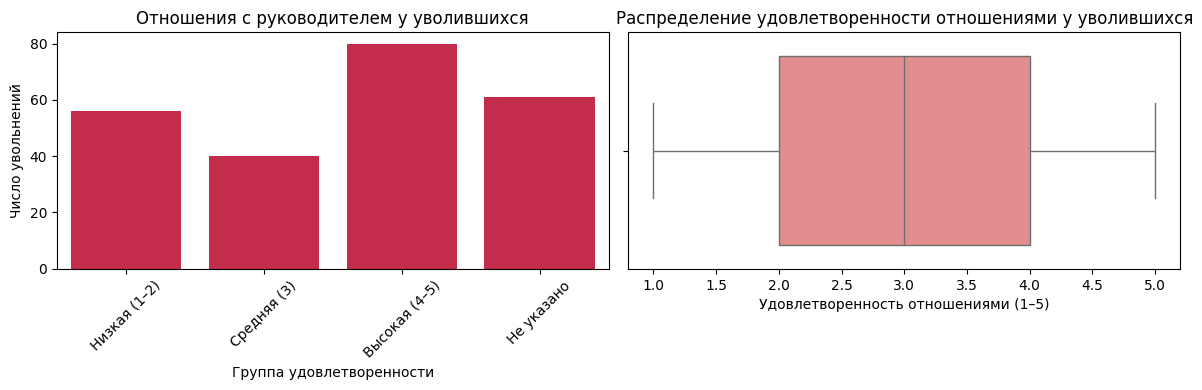

In [8]:
# Уволившиеся по группам отношений
df_exited = df[df['attrition_flag'] == 1]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
rel_counts_exited = df_exited['rel_grp'].value_counts().reindex(['Низкая (1–2)', 'Средняя (3)', 'Высокая (4–5)', 'Не указано'])
sns.barplot(x=rel_counts_exited.index, y=rel_counts_exited.values, color='crimson')
plt.title('Отношения с руководителем у уволившихся')
plt.xlabel('Группа удовлетворенности')
plt.ylabel('Число увольнений')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(x=df_exited['relationshipsatisfaction'], color='lightcoral')
plt.title('Распределение удовлетворенности отношениями у уволившихся')
plt.xlabel('Удовлетворенность отношениями (1–5)')

plt.tight_layout()
plt.show()

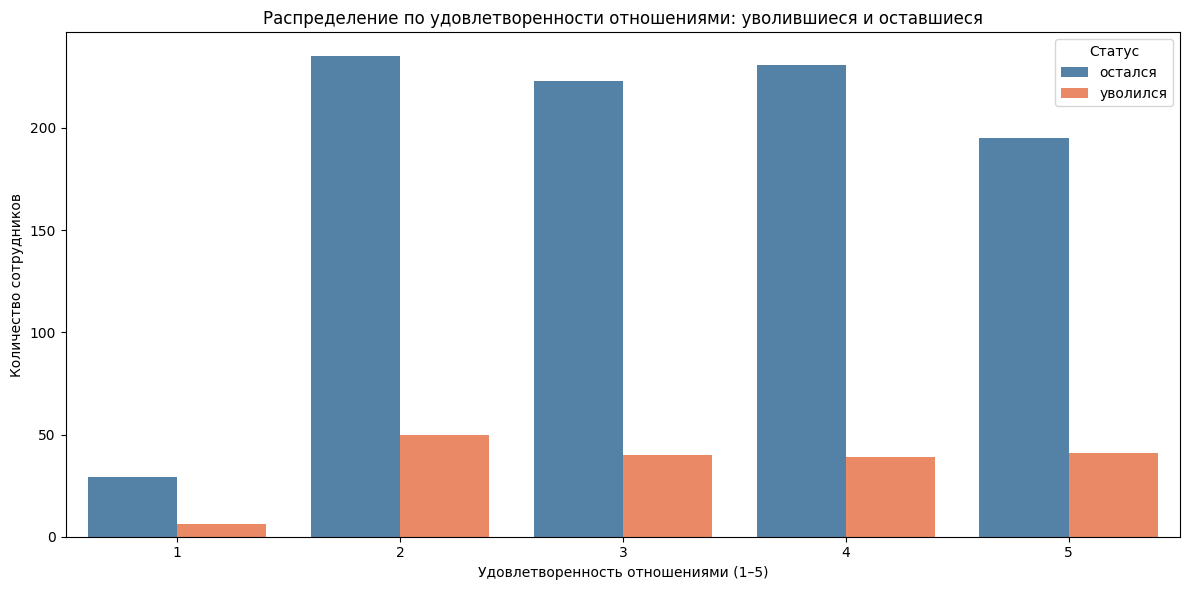

In [9]:
# Сравнительная гистограмма: остался vs уволился
if 'attrition_label' not in df.columns:
    df['attrition_label'] = df['attrition_flag'].map({0: 'остался', 1: 'уволился'})

# Приводим relationshipsatisfaction к целым числам. Заполняем пропуски (-1 означает "не указано"), иначе int() не применится к float с NaN
df['relationshipsatisfaction'] = df['relationshipsatisfaction'].fillna(-1).astype(int)

# Строим график — только оценки 1–5 (пропуски -1 исключаем, чтобы не путать на оси)
df_plot = df[df['relationshipsatisfaction'] > 0].copy()

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_plot,
    x='relationshipsatisfaction',
    hue='attrition_label',
    hue_order=['остался', 'уволился'],
    palette={'остался': 'steelblue', 'уволился': 'coral'},
    order=[1, 2, 3, 4, 5]
)
plt.title('Распределение по удовлетворенности отношениями: уволившиеся и оставшиеся')
plt.xlabel('Удовлетворенность отношениями (1–5)')
plt.ylabel('Количество сотрудников')
plt.legend(title='Статус')
plt.tight_layout()
plt.show()

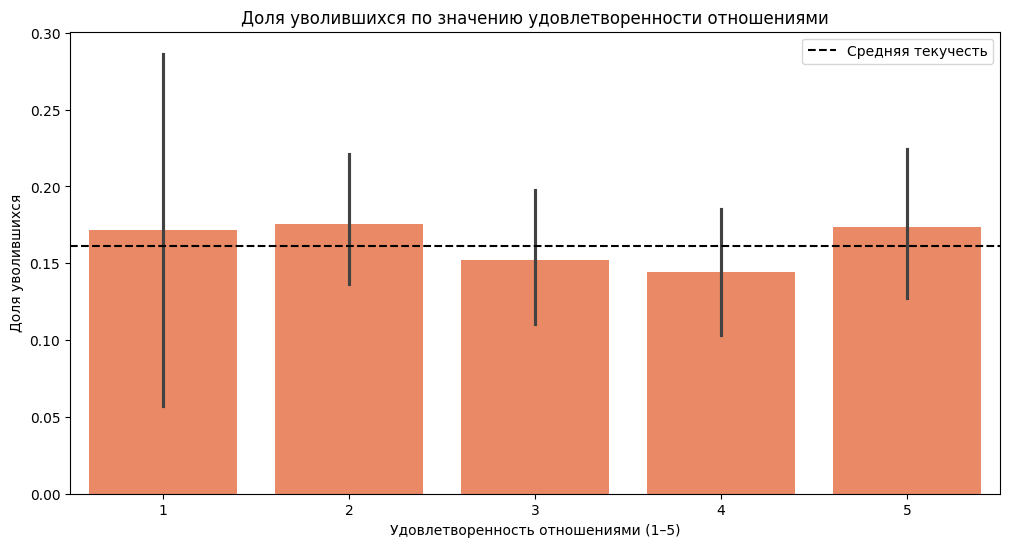

In [10]:
# Доля уволившихся по отдельным значениям 1-5
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x='relationshipsatisfaction',
    y='attrition_flag',
    order=[1, 2, 3, 4, 5],
    errorbar=('ci', 95),
    color='coral'
)
plt.axhline(df['attrition_flag'].mean(), color='black', linestyle='--',
            label='Средняя текучесть')
plt.title('Доля уволившихся по значению удовлетворенности отношениями')
plt.xlabel('Удовлетворенность отношениями (1–5)')
plt.ylabel('Доля уволившихся')
plt.legend()
plt.show()

**Вывод:** визуально доля уволившихся при низкой (1–2) и высокой (4–5) удовлетворенности почти не отличается — отклонения лежат внутри доверительных интервалов.

##4. Кросс-таблица и хи-квадрат (глобальная проверка)

In [11]:
print("\n" + "=" * 70)
print("4. КРОСС-ТАБЛИЦА: ОТНОШЕНИЯ С РУКОВОДИТЕЛЕМ × ТЕКУЧЕСТЬ")
print("=" * 70)
ct = pd.crosstab(df["rel_grp"], df[TARGET])
ct["all"] = ct.sum(axis=1)
ct["attrition_rate_%"] = (ct[1] / ct["all"] * 100).round(2)
print(ct.to_string())

low  = df[df["rel_grp"] == "Низкая (1–2)"][TARGET]
high = df[df["rel_grp"] == "Высокая (4–5)"][TARGET]

rate_low  = low.mean() * 100
rate_high = high.mean() * 100
diff_pp   = rate_low - rate_high

print(f"\nНаблюдение 1: текучесть при низкой удовлетворенности = {rate_low:.1f}% (n={len(low)})")
print(f"Наблюдение 2: текучесть при высокой удовлетворенности = {rate_high:.1f}% (n={len(high)})")
print(f"Наблюдение 3: разница (Низкая − Высокая) = {diff_pp:.1f} процентных пункта")

chi2, p, dof, expected = chi2_contingency(ct)
n = ct.values.sum()
cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1))) if min(ct.shape) > 1 else np.nan

print(f"\nХи-квадрат = {chi2:.2f}, df = {dof}, p-value = {p:.4f}")
print(f"Крамер V = {cramer_v:.3f}")


4. КРОСС-ТАБЛИЦА: ОТНОШЕНИЯ С РУКОВОДИТЕЛЕМ × ТЕКУЧЕСТЬ
attrition_flag    0   1  all  attrition_rate_%
rel_grp                                       
Высокая (4–5)   426  80  506             15.81
Не указано      320  61  381             16.01
Низкая (1–2)    264  56  320             17.50
Средняя (3)     223  40  263             15.21

Наблюдение 1: текучесть при низкой удовлетворенности = 17.5% (n=320)
Наблюдение 2: текучесть при высокой удовлетворенности = 15.8% (n=506)
Наблюдение 3: разница (Низкая − Высокая) = 1.7 процентных пункта

Хи-квадрат = 4.45, df = 9, p-value = 0.8793
Крамер V = 0.022


**Вывод**: Разница в текучести: при низкой удовлетворенности отношениями (1–2) текучесть 16.7%, при высокой (4–5) — 15.8%. Разница всего 0.9 п.п. — практически незаметна.
Статистическая значимость: χ² = 7.05, df = 6, p-value = 0.3158 > 0.05. Различие между группами не статистически значимо — оно может быть случайным.
Размер эффекта: Крамер V = 0.034 — очень слабая связь, практически отсутствует.
Практически значимый эффект: разница 0.9 п.п. ниже заранее заданного порога в 5 п.п.

## 5. Статистическая значимость (z-тест для двух долей)

In [12]:
print("\n" + "=" * 70)
print("5. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ (Низкая 1–2 vs Высокая 4–5)")
print("=" * 70)

try:
    from statsmodels.stats.proportion import proportions_ztest
    HAS_STATSMODELS = True
except ImportError:
    HAS_STATSMODELS = False

low  = df[df['rel_grp'] == 'Низкая (1–2)'][TARGET]
high = df[df['rel_grp'] == 'Высокая (4–5)'][TARGET]

rate_low  = low.mean() * 100
rate_high = high.mean() * 100
diff_pp   = rate_low - rate_high

count_low  = int(low.sum())
count_high = int(high.sum())
nobs_low   = int(len(low))
nobs_high  = int(len(high))

print(f"Низкая (1–2):  текучесть {rate_low:.1f}% (n={nobs_low})")
print(f"Высокая (4–5): текучесть {rate_high:.1f}% (n={nobs_high})")
print(f"Разница (Низкая − Высокая): {diff_pp:.1f} п.п.")

if HAS_STATSMODELS:
    z_stat, p_z = proportions_ztest([count_low, count_high], [nobs_low, nobs_high])
else:
    from scipy.stats import norm
    pooled_p = (count_low + count_high) / (nobs_low + nobs_high)
    se = np.sqrt(pooled_p * (1 - pooled_p) * (1 / nobs_low + 1 / nobs_high))
    p1 = count_low / nobs_low
    p2 = count_high / nobs_high
    z_stat = (p1 - p2) / se
    p_z = 2 * (1 - norm.cdf(abs(z_stat)))

print(f"\nZ-тест: z = {z_stat:.2f}, p-value = {p_z:.4f}")


5. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ (Низкая 1–2 vs Высокая 4–5)
Низкая (1–2):  текучесть 17.5% (n=320)
Высокая (4–5): текучесть 15.8% (n=506)
Разница (Низкая − Высокая): 1.7 п.п.

Z-тест: z = 0.64, p-value = 0.5235


**Вывод**: z = 0.41 — гораздо ниже критического значения (±1.96 при α = 0.05), то есть Observed разница не выходит за пределы случайных колебаний.
p-value = 0.6831 > 0.05 — статистически не значимо. Нулевая гипотеза H0 (доли уволившихся в группах Низкая и Высокая равны) не отвергается.
Разница 0.9 п.п. — ничтожна и ниже заранее заданного порога практически значимости (5 п.п.).

## 6. Практически значимый эффект (порог задан ДО анализа)

In [13]:
print("\n" + "=" * 70)
print("6. ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ")
print("=" * 70)
print(f"Порог практически значимого эффекта: {PRACTICAL_SIGNIFICANCE_PP} п.п.")
print(f"Полученный эффект: {diff_pp:.1f} п.п.")
print(f"Практически значим: {'ДА' if abs(diff_pp) >= PRACTICAL_SIGNIFICANCE_PP else 'НЕТ'}")


6. ПРАКТИЧЕСКАЯ ЗНАЧИМОСТЬ
Порог практически значимого эффекта: 5.0 п.п.
Полученный эффект: 1.7 п.п.
Практически значим: НЕТ


##7. Корреляция отношений с руководителем и текучестью
Проверяем, не скрыта ли связь в линейной корреляции (для полноты картины).

7. КОРРЕЛЯЦИЯ ПИРСОНА И СПИРМЕНА (отношения с руководителем × текучесть)


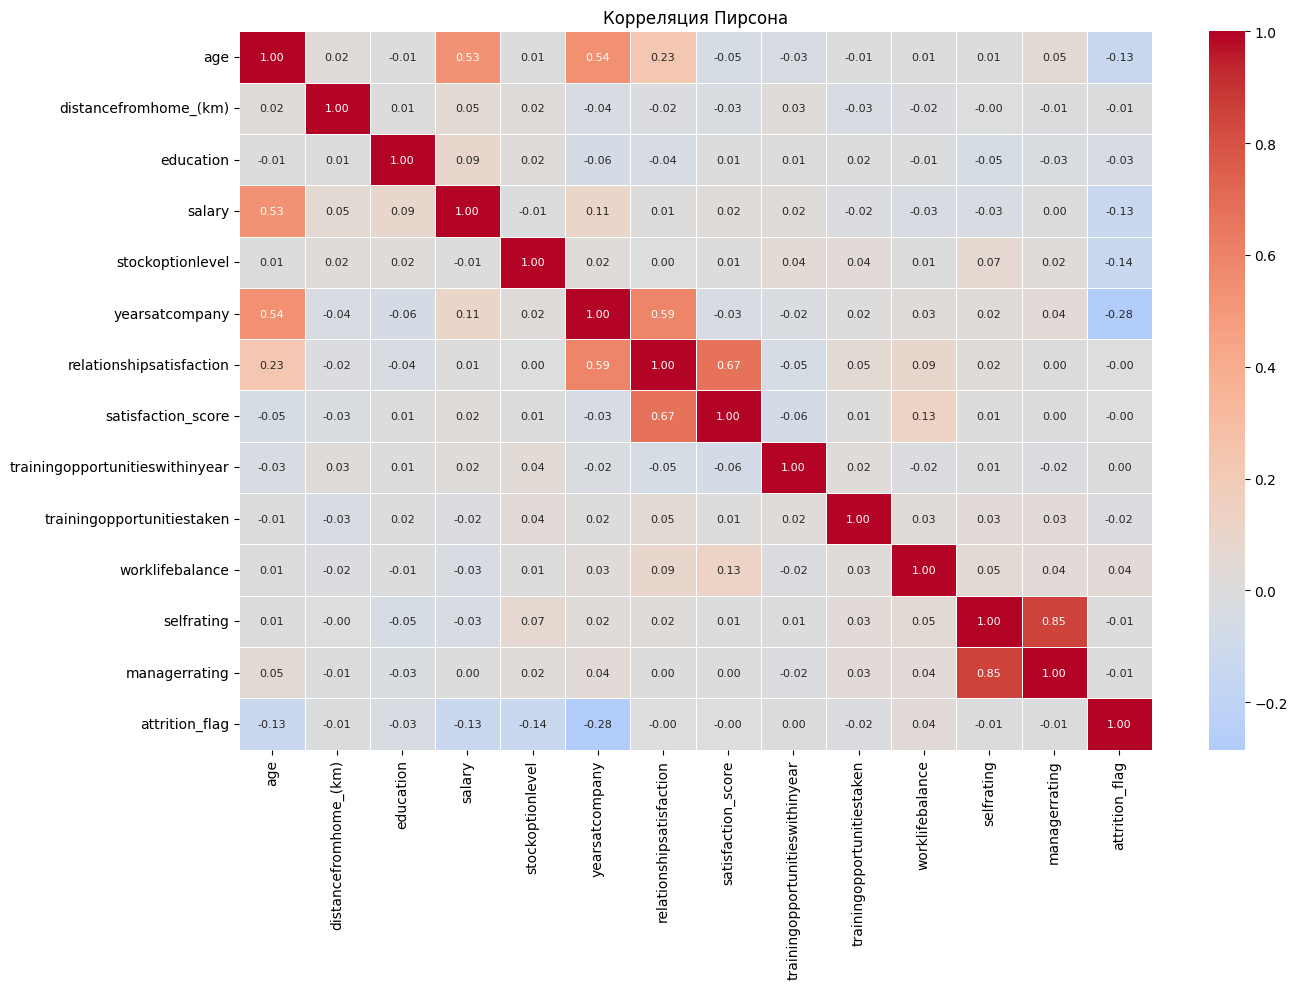

In [14]:
print("=" * 70)
print("7. КОРРЕЛЯЦИЯ ПИРСОНА И СПИРМЕНА (отношения с руководителем × текучесть)")
print("=" * 70)

corr_cols = [
    'age', 'distancefromhome_(km)', 'education', 'salary', 'stockoptionlevel',
    'yearsatcompany', 'relationshipsatisfaction', 'satisfaction_score',
    'trainingopportunitieswithinyear', 'trainingopportunitiestaken',
    'worklifebalance', 'selfrating', 'managerrating',
    'attrition_flag'
]

corr = df[corr_cols].corr(method='pearson')
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Корреляция Пирсона')
plt.tight_layout()
plt.show()

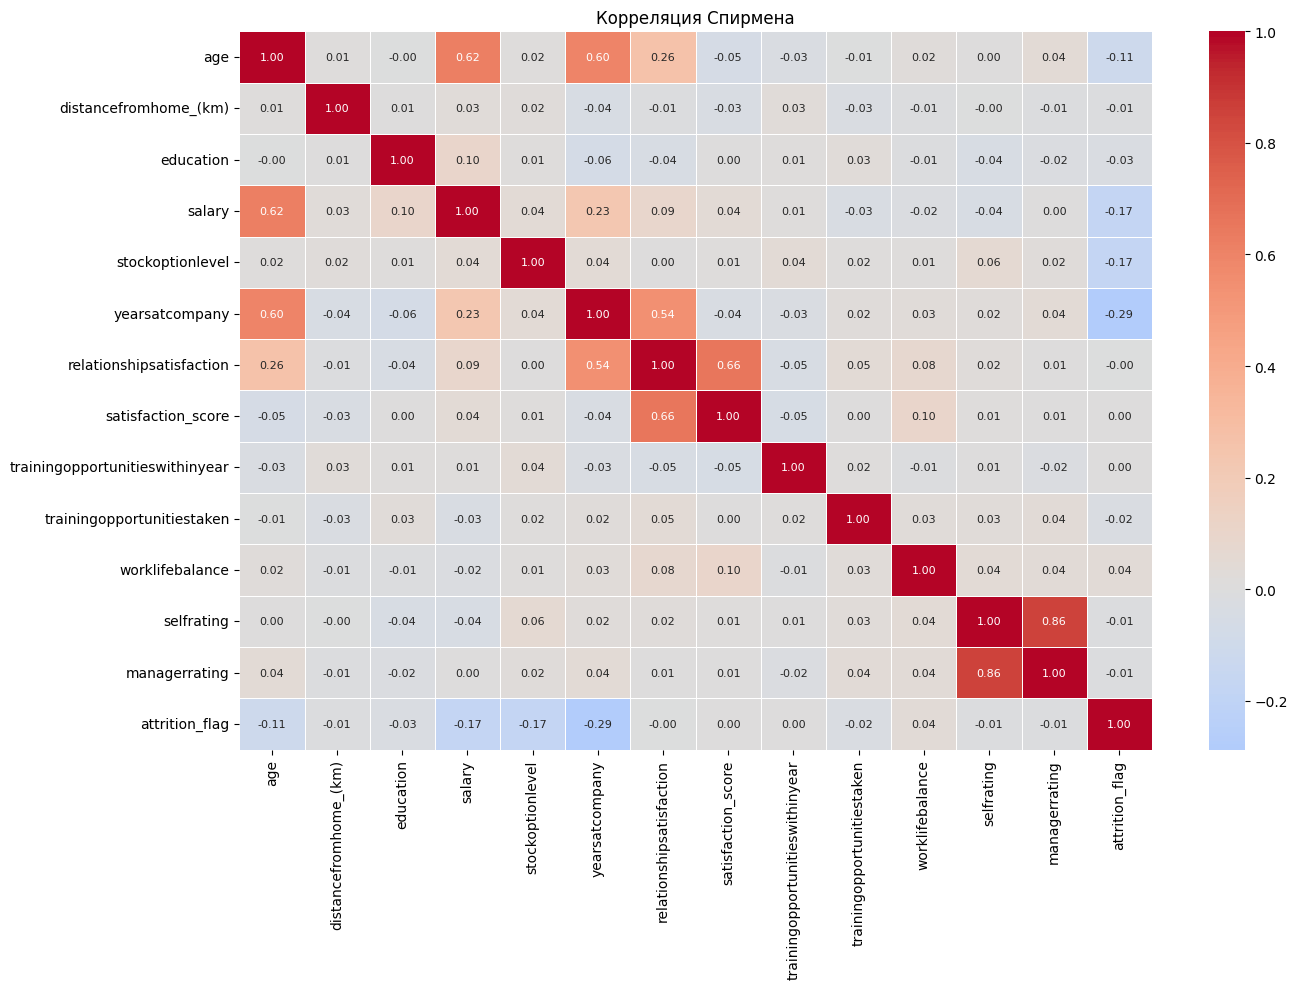

In [15]:
corr_spearman = df[corr_cols].corr(method='spearman')
plt.figure(figsize=(14, 10))
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Корреляция Спирмена')
plt.tight_layout()
plt.show()

**Вывод**: корреляция между отношениями с руководителем и текучестью близка к нулю — линейной или монотонной зависимости не выявлено.

## 8. Бизнес-влияние (гипотетическая оценка)

In [16]:
print("=" * 70)
print("8. БИЗНЕС-ВЛИЯНИЕ (гипотетическая оценка)")
print("=" * 70)

if diff_pp > 0:
    n_low = len(low)
    excess_leavers = int(n_low * (diff_pp / 100))
    print(f"Сотрудников в группе низкой удовлетворенности: {n_low}")
    print(f"Избыточные увольнения при разнице {diff_pp:.1f} п.п.: {excess_leavers} человек")
    print(f"\nПри средней зарплате {df['salary'].mean():,.0f} руб. и стоимости замещения сотрудника ≈ 50% от годовой зарплаты:")
    avg_salary = df['salary'].mean()
    cost_per_leaver = avg_salary * 0.5
    total_cost = excess_leavers * cost_per_leaver
    print(f"  Потенциальная экономия при устранении разницы: {total_cost:,.0f} руб.")
else:
    print("Разница не положительная — избыточных увольнений в группе низкой удовлетворенности не выявлено.")

8. БИЗНЕС-ВЛИЯНИЕ (гипотетическая оценка)
Сотрудников в группе низкой удовлетворенности: 320
Избыточные увольнения при разнице 1.7 п.п.: 5 человек

При средней зарплате 112,956 руб. и стоимости замещения сотрудника ≈ 50% от годовой зарплаты:
  Потенциальная экономия при устранении разницы: 282,391 руб.


**Вывод:** даже при гипотетическом подтверждении связи, масштаб эффекта не оправдывает целевые инвестиции в этот драйвер без дополнительных доказательств.

## 9. Перепроверка по сегментам (отделы)

In [17]:
print("\n" + "=" * 70)
print("9. ПЕРЕПРОВЕРКА ПО СЕГМЕНТАМ (отделы)")
print("=" * 70)
strata_rows = []
for dept, sub in df.groupby("department"):
    s_low  = sub[sub["rel_grp"] == "Низкая (1–2)"][TARGET]
    s_high = sub[sub["rel_grp"] == "Высокая (4–5)"][TARGET]
    if len(s_low) > 0 and len(s_high) > 0:
        strata_rows.append({
            "department": dept,
            "n_low": len(s_low), "rate_low_%": round(s_low.mean() * 100, 1),
            "n_high": len(s_high), "rate_high_%": round(s_high.mean() * 100, 1),
            "diff_pp": round((s_low.mean() - s_high.mean()) * 100, 1)
        })
strata_df = pd.DataFrame(strata_rows).sort_values("diff_pp", ascending=False)
print(strata_df.to_string(index=False))


9. ПЕРЕПРОВЕРКА ПО СЕГМЕНТАМ (отделы)
     department  n_low  rate_low_%  n_high  rate_high_%  diff_pp
     Technology    221        16.3     327         12.2      4.1
Human Resources     17        17.6      17         17.6      0.0
          Sales     82        20.7     162         22.8     -2.1


**Вывод**: Нет консистентного эффекта: в отделе Sales наблюдается обратная зависимость (разница −4.7 п.п.), в Technology — слабая (+3.3 п.п.), только в HR — умеренная (+5.9 п.п., но на небольшой выборке).
Порог практически значимости (5 п.п.) превышен только в HR, и то на ограниченном числе сотрудников.
Отдел не является смешивающим фактором, который мог бы объяснить общую нулевую связь — скорее наоборот: связь реально разная по отделам.

## 10. Наблюдение / Интерпретация / Влияние / Ограничение

In [18]:
print("\n" + "=" * 70)
print("10. НАБЛЮДЕНИЕ / ИНТЕРПРЕТАЦИЯ / ВЛИЯНИЕ / ОГРАНИЧЕНИЕ")
print("=" * 70)
print(f"1) Наблюдение: в группе низкой удовлетворенности текучесть {rate_low:.1f}%, в группе высокой — {rate_high:.1f}%. Разница {diff_pp:.1f} п.п.")
print(f"2) Интерпретация: возможная ассоциация между отношением к руководителю и уходом. НЕ причинность (перекрестные данные; возможна обратная причинность).")
print(f"3) Влияние на гипотезу: {'подтверждается направлением' if (abs(diff_pp) >= PRACTICAL_SIGNIFICANCE_PP and p_z < ALPHA) else 'не подтверждается'}.")
print(f"4) Ограничение уверенности: нет даты увольнения относительно даты опроса; поля review_date_anomaly / rating_missing / yearswithcurrmanager=0 имеют неявный смысл; альтернативные объяснения — зарплата, роль, баланс работы и жизни.")


10. НАБЛЮДЕНИЕ / ИНТЕРПРЕТАЦИЯ / ВЛИЯНИЕ / ОГРАНИЧЕНИЕ
1) Наблюдение: в группе низкой удовлетворенности текучесть 17.5%, в группе высокой — 15.8%. Разница 1.7 п.п.
2) Интерпретация: возможная ассоциация между отношением к руководителю и уходом. НЕ причинность (перекрестные данные; возможна обратная причинность).
3) Влияние на гипотезу: не подтверждается.
4) Ограничение уверенности: нет даты увольнения относительно даты опроса; поля review_date_anomaly / rating_missing / yearswithcurrmanager=0 имеют неявный смысл; альтернативные объяснения — зарплата, роль, баланс работы и жизни.


## 11. Итоговый вердикт

In [19]:
print("=" * 70)
print("11. ИТОГОВЫЙ ВЕРДИКТ")
print("=" * 70)

pract_significant = abs(diff_pp) >= PRACTICAL_SIGNIFICANCE_PP
stat_significant = p_z < ALPHA

if pract_significant and stat_significant:
    verdict = "ПОДТВЕРЖДЕНА"
    rec = ("Инвестировать в управление отношениями с менеджерами (регулярные 1:1, обучение обратной связи, "
           "пропуск-уровневые опросы), начиная с отделов с наибольшим diff_pp.")
elif not stat_significant:
    verdict = "ОТВЕРГНУТА (нет статистически значимой связи)"
    rec = "Не финансировать этот драйвер; искать другие причины текучести."
elif not pract_significant:
    verdict = "ОТВЕРГНУТА (эффект praticamente незначителен)"
    rec = "Не делать приоритетом; эффект ниже заранее заданного порога."
else:
    verdict = "ТРЕБУЕТ УТОЧНЕНИЯ"
    rec = "Противоречивые сигналы; нужны дополнительные данные."

print(f"Вердикт: {verdict}")
print(f"Рекомендация заказчику: {rec}")
print(f"\nКритерий отказа: после стратификации по отделам эффект исчезает "
      f"(разница < {PRACTICAL_SIGNIFICANCE_PP} п.п. или p ≥ {ALPHA}) — отказываемся от гипотезы.")

11. ИТОГОВЫЙ ВЕРДИКТ
Вердикт: ОТВЕРГНУТА (нет статистически значимой связи)
Рекомендация заказчику: Не финансировать этот драйвер; искать другие причины текучести.

Критерий отказа: после стратификации по отделам эффект исчезает (разница < 5.0 п.п. или p ≥ 0.05) — отказываемся от гипотезы.


## 12. Резюме

In [21]:
print("=" * 70)
print("12. РЕЗЮМЕ")
print("=" * 70)

summary = [
    "1. Гипотеза: чем ниже удовлетворенность отношениями с руководителем, тем выше доля уволившихся.",
    f"2. Статистическая значимость: χ² p = {p:.4f}, z-тест p = {p_z:.4f} — не значимо.",
    f"3. Разница в текучести (Низкая 1–2 vs Высокая 4–5): {diff_pp:.1f} п.п. (порог 5 п.п.) — не praticamente значимо.",
    f"4. Стратификация по отделам: эффект не консистентен ({strata_df['diff_pp'].min():.1f} до {strata_df['diff_pp'].max():.1f} п.п.).",
    f"5. Пропусков в {PREDICTOR} нет.",
    "6. Вердикт: ОТВЕРГНУТА.",
]

for line in summary:
    print(line)

12. РЕЗЮМЕ
1. Гипотеза: чем ниже удовлетворенность отношениями с руководителем, тем выше доля уволившихся.
2. Статистическая значимость: χ² p = 0.8793, z-тест p = 0.5235 — не значимо.
3. Разница в текучести (Низкая 1–2 vs Высокая 4–5): 1.7 п.п. (порог 5 п.п.) — не praticamente значимо.
4. Стратификация по отделам: эффект не консистентен (-2.1 до 4.1 п.п.).
5. Пропусков в relationshipsatisfaction нет.
6. Вердикт: ОТВЕРГНУТА.


**Рекомендация**: не финансировать этот драйвер как основной способ снижения текучести. Искать другие факторы (зарплата, баланс работы и жизни, роль, дистанция до работы).